In [4]:
import pandas as pd

df = pd.read_csv(r"C:\Users\B M Lavanya\Downloads\synthetic_logs.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLabel distribution:")
print(df["label"].value_counts())

Shape: (5000, 12)

Columns:
Index(['user_id', 'timestamp', 'login_hour', 'country', 'ip_address', 'device',
       'resource', 'auth_method', 'session_duration', 'command_count',
       'failed_attempts', 'label'],
      dtype='object')

Missing values:
user_id             0
timestamp           0
login_hour          0
country             0
ip_address          0
device              0
resource            0
auth_method         0
session_duration    0
command_count       0
failed_attempts     0
label               0
dtype: int64

Duplicate rows: 0

Label distribution:
label
Normal               4838
Impossible Travel      44
Lateral Movement       42
Device Spoofing        40
Brute Force            36
Name: count, dtype: int64


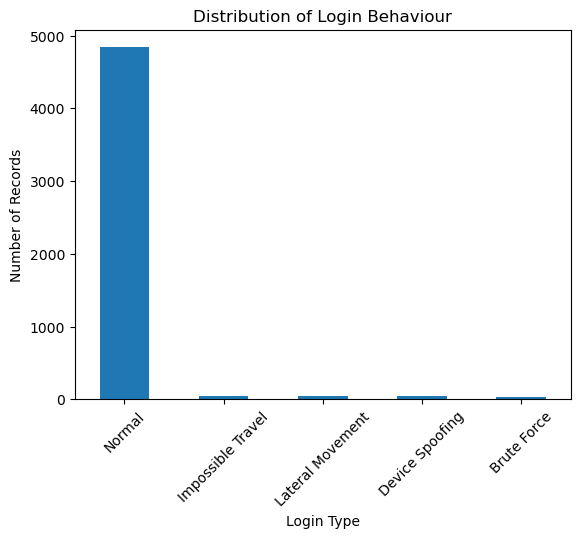

In [5]:
import matplotlib.pyplot as plt

df["label"].value_counts().plot(kind="bar")

plt.title("Distribution of Login Behaviour")
plt.xlabel("Login Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.show()

In [6]:
df.groupby("label")[[
    "login_hour",
    "session_duration",
    "command_count",
    "failed_attempts"
]].mean()

,login_hour,session_duration,command_count,failed_attempts
label,,,,
Brute Force,11.777778,35.944444,5.694444,19.416667
Device Spoofing,9.925000,35.900000,5.025000,0.000000
Impossible Travel,10.704545,38.090909,6.636364,0.000000
Lateral Movement,9.904762,39.309524,52.690476,0.000000
Normal,11.391691,37.713105,6.005994,0.000000


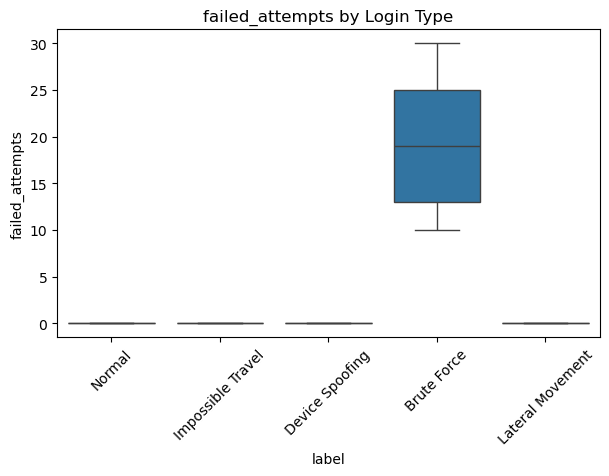

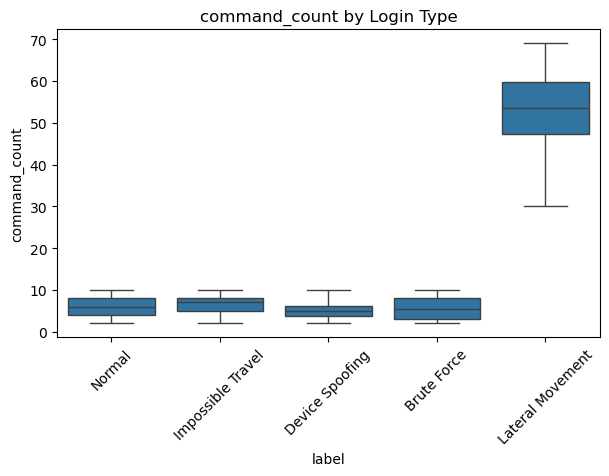

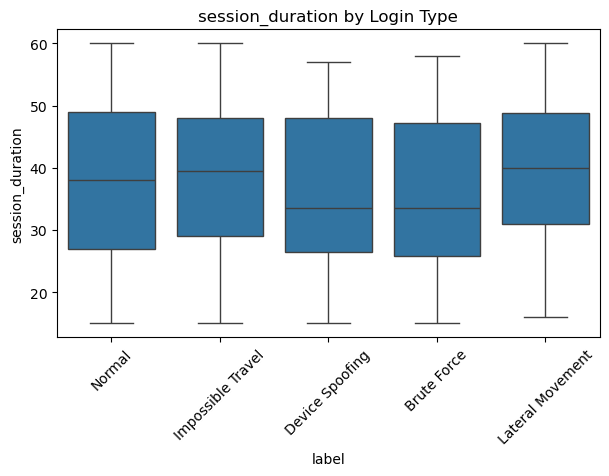

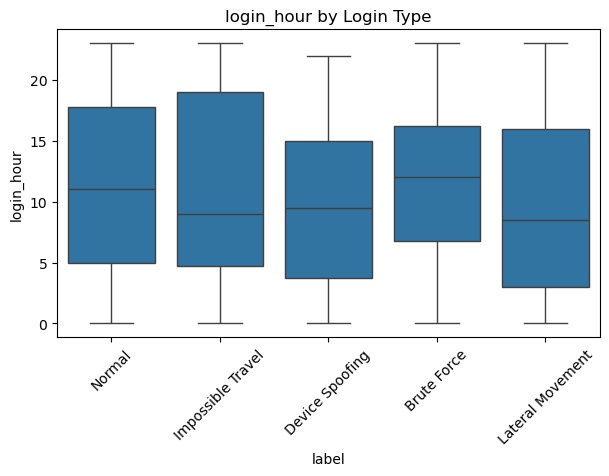

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

features = ["failed_attempts", "command_count", "session_duration", "login_hour"]

for feature in features:
    plt.figure(figsize=(7,4))
    sns.boxplot(x="label", y=feature, data=df)
    plt.title(f"{feature} by Login Type")
    plt.xticks(rotation=45)
    plt.show()

In [8]:
for col in ["country", "device", "auth_method", "resource"]:
    print("\n", col)
    print(pd.crosstab(df[col], df["label"]))
    


 country
label      Brute Force  Device Spoofing  Impossible Travel  Lateral Movement  \
country                                                                        
Germany              0                0                 19                 0   
India               36               40                  0                42   
Singapore            0                0                 16                 0   
USA                  0                0                  9                 0   

label      Normal  
country            
Germany         0  
India        4838  
Singapore       0  
USA             0  

 device
label    Brute Force  Device Spoofing  Impossible Travel  Lateral Movement  \
device                                                                       
Linux              0               40                  0                 0   
Windows           36                0                 44                42   

label    Normal  
device           
Linux         0  
Windows    48

In [9]:
df["suspicious"] = (df["label"] != "Normal").astype(int)

print(df["suspicious"].value_counts())

suspicious
0    4838
1     162
Name: count, dtype: int64


In [10]:
features = [
    "login_hour",
    "session_duration",
    "command_count",
    "failed_attempts",
    "country",
    "device",
    "resource"
]

X = df[features]
y = df["suspicious"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5000, 7)
y shape: (5000,)


In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (4000, 7)
Testing data: (1000, 7)


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = ["country", "device", "resource"]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (4000, 13)
Processed testing shape: (1000, 13)


In [13]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_lr.fit(X_train_processed, y_train)

y_pred = model_lr.predict(X_test_processed)

print("Predictions completed!")

Predictions completed!


In [14]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1-score :", f1_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

y_prob = model_lr.predict_proba(X_test_processed)[:, 1]
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Confusion Matrix:
[[968   0]
 [  0  32]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       968
           1       1.00      1.00      1.00        32

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000

ROC-AUC  : 1.0


In [15]:
import pandas as pd

feature_names = preprocessor.get_feature_names_out()

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model_lr.coef_[0]
})

coefficients["Absolute_Importance"] = coefficients["Coefficient"].abs()

coefficients.sort_values(
    "Absolute_Importance",
    ascending=False
).head(10)

,Feature,Coefficient,Absolute_Importance
1,cat__country_India,-7.044966,7.044966
4,cat__device_Linux,5.146404,5.146404
5,cat__device_Windows,-5.039146,5.039146
2,cat__country_Singapore,2.669361,2.669361
0,cat__country_Germany,2.418012,2.418012
3,cat__country_USA,2.064851,2.064851
6,cat__resource_Admin Panel,1.583438,1.583438
12,remainder__failed_attempts,1.143543,1.143543
8,cat__resource_Email,-0.752832,0.752832
7,cat__resource_CRM,-0.723349,0.723349


In [16]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    model_lr,
    X_train_processed,
    y_train,
    cv=5,
    scoring="f1"
)

print("F1 scores:", scores)
print("Mean F1:", scores.mean())

F1 scores: [1. 1. 1. 1. 1.]
Mean F1: 1.0


In [17]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

model_dt.fit(X_train_processed, y_train)

y_pred_dt = model_dt.predict(X_test_processed)

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       968
           1       1.00      1.00      1.00        32

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)

model_knn = KNeighborsClassifier(n_neighbors=5)

model_knn.fit(X_train_scaled, y_train)

y_pred_knn = model_knn.predict(X_test_scaled)

print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       968
           1       1.00      1.00      1.00        32

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [19]:
print(pd.crosstab(df["country"], df["suspicious"], normalize="index"))
print(pd.crosstab(df["device"], df["suspicious"], normalize="index"))
print(pd.crosstab(df["resource"], df["suspicious"], normalize="index"))

suspicious        0        1
country                     
Germany     0.00000  1.00000
India       0.97619  0.02381
Singapore   0.00000  1.00000
USA         0.00000  1.00000
suspicious         0         1
device                        
Linux       0.000000  1.000000
Windows     0.975403  0.024597
suspicious          0         1
resource                       
Admin Panel  0.000000  1.000000
CRM          0.974338  0.025662
Email        0.977273  0.022727


In [20]:
# Sort logins by user and time
df["timestamp"] = pd.to_datetime(df["timestamp"])

df = df.sort_values(["user_id", "timestamp"])

# Previous device and country for each user
df["previous_device"] = df.groupby("user_id")["device"].shift(1)
df["previous_country"] = df.groupby("user_id")["country"].shift(1)

# Detect changes
df["device_change"] = (
    (df["device"] != df["previous_device"]) &
    (df["previous_device"].notna())
).astype(int)

df["location_change"] = (
    (df["country"] != df["previous_country"]) &
    (df["previous_country"].notna())
).astype(int)

print(df[[
    "user_id",
    "device",
    "previous_device",
    "device_change",
    "country",
    "previous_country",
    "location_change"
]].head(15))

       user_id   device previous_device  device_change country  \
4372  user_001  Windows             NaN              0   India   
3456  user_001  Windows         Windows              0   India   
1302  user_001  Windows         Windows              0   India   
1621  user_001  Windows         Windows              0   India   
494   user_001  Windows         Windows              0   India   
3807  user_001  Windows         Windows              0   India   
3633  user_001  Windows         Windows              0   India   
2263  user_001  Windows         Windows              0   India   
62    user_001    Linux         Windows              1   India   
1612  user_001  Windows           Linux              1   India   
3156  user_001  Windows         Windows              0   India   
4164  user_001  Windows         Windows              0   India   
4811  user_001  Windows         Windows              0   India   
1146  user_001  Windows         Windows              0   India   
4697  user

In [21]:
print(pd.crosstab(df["device_change"], df["suspicious"], normalize="index"))

print("\nLocation change:")
print(pd.crosstab(df["location_change"], df["suspicious"], normalize="index"))

suspicious           0        1
device_change                  
0              0.97501  0.02499
1              0.50000  0.50000

Location change:
suspicious              0         1
location_change                    
0                0.975977  0.024023
1                0.500000  0.500000


In [22]:
features = [
    "login_hour",
    "session_duration",
    "command_count",
    "failed_attempts",
    "country",
    "device",
    "resource",
    "device_change",
    "location_change"
]

X = df[features]
y = df["suspicious"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (5000, 9)
y shape: (5000,)


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (4000, 9)
Testing: (1000, 9)


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "country",
    "device",
    "resource"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ],
    remainder="passthrough"
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (4000, 15)
Processed testing shape: (1000, 15)


In [25]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

model_lr.fit(X_train_processed, y_train)

y_pred_lr = model_lr.predict(X_test_processed)

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       968
           1       1.00      1.00      1.00        32

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [26]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

model_dt.fit(X_train_processed, y_train)

y_pred_dt = model_dt.predict(X_test_processed)

print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       968
           1       1.00      1.00      1.00        32

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [27]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_processed)
X_test_scaled = scaler.transform(X_test_processed)

model_knn = KNeighborsClassifier(n_neighbors=5)

model_knn.fit(X_train_scaled, y_train)

y_pred_knn = model_knn.predict(X_test_scaled)

print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       968
           1       1.00      1.00      1.00        32

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000



In [28]:
features_final = [
    "login_hour",
    "failed_attempts",
    "session_duration",
    "device_change",
    "location_change"
]

X_final = df[features_final]
y_final = df["suspicious"]

print(X_final.shape)

(5000, 5)


In [29]:
from sklearn.model_selection import train_test_split

X_train_final, X_test_final, y_train_final, y_test_final = train_test_split(
    X_final,
    y_final,
    test_size=0.2,
    random_state=42,
    stratify=y_final
)

print("Training:", X_train_final.shape)
print("Testing:", X_test_final.shape)

Training: (4000, 5)
Testing: (1000, 5)


In [30]:
from sklearn.linear_model import LogisticRegression

final_lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

final_lr.fit(X_train_final, y_train_final)

y_pred_final = final_lr.predict(X_test_final)

print(classification_report(y_test_final, y_pred_final))

              precision    recall  f1-score   support

           0       0.99      0.98      0.98       968
           1       0.49      0.62      0.55        32

    accuracy                           0.97      1000
   macro avg       0.74      0.80      0.77      1000
weighted avg       0.97      0.97      0.97      1000



In [31]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_final, y_pred_final)

print(cm)

[[947  21]
 [ 12  20]]


In [32]:
from sklearn.tree import DecisionTreeClassifier

final_dt = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

final_dt.fit(X_train_final, y_train_final)

y_pred_dt_final = final_dt.predict(X_test_final)

print(classification_report(y_test_final, y_pred_dt_final))

              precision    recall  f1-score   support

           0       0.98      0.96      0.97       968
           1       0.25      0.44      0.31        32

    accuracy                           0.94      1000
   macro avg       0.61      0.70      0.64      1000
weighted avg       0.96      0.94      0.95      1000



In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

scaler_final = StandardScaler()

X_train_scaled_final = scaler_final.fit_transform(X_train_final)
X_test_scaled_final = scaler_final.transform(X_test_final)

final_knn = KNeighborsClassifier(n_neighbors=5)

final_knn.fit(X_train_scaled_final, y_train_final)

y_pred_knn_final = final_knn.predict(X_test_scaled_final)

print(classification_report(y_test_final, y_pred_knn_final))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98       968
           1       0.45      0.44      0.44        32

    accuracy                           0.96      1000
   macro avg       0.72      0.71      0.71      1000
weighted avg       0.96      0.96      0.96      1000



In [34]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

y_prob_final = final_lr.predict_proba(X_test_final)[:, 1]

for threshold in [0.5, 0.4, 0.3, 0.2]:
    
    y_pred_threshold = (y_prob_final >= threshold).astype(int)
    
    print("Threshold:", threshold)
    print("Precision:", precision_score(y_test_final, y_pred_threshold))
    print("Recall:", recall_score(y_test_final, y_pred_threshold))
    print("F1:", f1_score(y_test_final, y_pred_threshold))
    print()

Threshold: 0.5
Precision: 0.4878048780487805
Recall: 0.625
F1: 0.547945205479452

Threshold: 0.4
Precision: 0.4878048780487805
Recall: 0.625
F1: 0.547945205479452

Threshold: 0.3
Precision: 0.4878048780487805
Recall: 0.625
F1: 0.547945205479452

Threshold: 0.2
Precision: 0.052313883299798795
Recall: 0.8125
F1: 0.09829867674858223



ROC-AUC: 0.8008942407024793


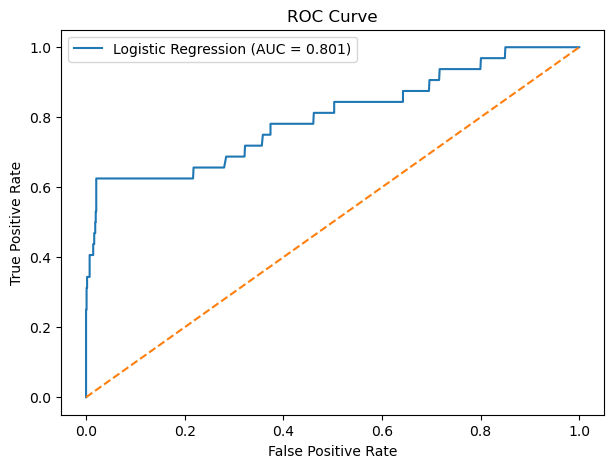

In [35]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

auc = roc_auc_score(y_test_final, y_prob_final)

print("ROC-AUC:", auc)

fpr, tpr, thresholds = roc_curve(y_test_final, y_prob_final)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [36]:
import joblib

joblib.dump(final_lr, "login_detection_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [37]:
loaded_model = joblib.load("login_detection_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!
